# chl vs b$_{bp}$ per DBO box — combined figure: scatters (a) + verdict table (b)

Remake of the chl-vs-bbp analysis from `1_pull_data/03_modis-bbp443-monthly.ipynb` (its "does the chl signal
carry through to backscatter" cell) as **one publication figure**: the 8 log–log scatter panels as
**panel a** and the per-box trend/verdict table rendered **in the figure as panel b**, with all
fonts sized for a slide/manuscript.

**Self-contained.** Loads the two monthly checkpoints from `$HOME`
(no earthaccess, no streaming):

| series | checkpoint | note |
|---|---|---|
| b$_{bp}$(443), monthly box means | `modis_bbp_dbo_ckpt.pkl` (`box_rows`) | GIOP |
| chl, monthly box means | `modis_chl_dbo_ckpt.pkl` | **standard `chlor_a`**, not AO.emp — same as the source notebook, so the numbers reproduce |

Estimators are verbatim from the source cell: Spearman r on log chl vs log bbp; deseasonalized
monthly-anomaly Theil–Sen trends (%/decade of the record mean) with AR(1)-adjusted Mann–Kendall
for chl, bbp, and the log₁₀(chl/bbp) ratio; the same verdict rules.

## 1. Imports

In [1]:
import pickle
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, theilslopes, kendalltau, norm
print("imports ok")

imports ok


## 2. Load the two checkpoints → per-box monthly series

In [2]:
BBP_CKPT = Path.home() / "modis_bbp_dbo_ckpt.pkl"  # add your path
CHL_CKPT = Path.home() / "modis_chl_dbo_ckpt.pkl"  # add your path

def _rows_to_das(rows):
    dts = sorted(rows); t = np.array([np.datetime64(pd.Timestamp(d).to_pydatetime().isoformat())
                                      for d in dts])
    boxes = sorted({n for d in dts for n in rows[d]})
    return {n: xr.DataArray(np.array([float(rows[d].get(n, np.nan)) for d in dts], float),
                            dims="time", coords={"time": t}) for n in boxes}

_o = pickle.load(open(BBP_CKPT, "rb"))
box_ts = _rows_to_das(_o["box_rows"] if isinstance(_o, dict) and "box_rows" in _o else _o)

_c = pickle.load(open(CHL_CKPT, "rb"))                       # plain {date: {box: val}} dict
chl_box_ts = _rows_to_das(_c)

for nm, d in (("bbp", box_ts), ("chl", chl_box_ts)):
    t = pd.to_datetime(next(iter(d.values()))["time"].values)
    print(f"{nm}: {len(t)} monthly steps  {t.min().date()} -> {t.max().date()}  | boxes: {list(d)}")

bbp: 257 monthly steps  2002-07-01 -> 2025-10-01  | boxes: ['DBO1', 'DBO2', 'DBO3', 'DBO4', 'DBO5', 'DBO6', 'DBO7', 'DBO8']
chl: 281 monthly steps  2002-07-01 -> 2025-11-01  | boxes: ['DBO1', 'DBO2', 'DBO3', 'DBO4', 'DBO5', 'DBO6', 'DBO7', 'DBO8']


## 3. Estimators — verbatim from the source notebook

In [3]:
def _st(p):
    return ("***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns") if np.isfinite(p) else "n/a"

def _l1(x):
    x = np.asarray(x, float); a, b = x[1:], x[:-1]; v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 5 else 0.0

def _tr(s):                     # deseasonalized monthly-anomaly trend -> (%/decade rel mean, p)
    moy = s["time"].dt.month
    an = (s.assign_coords(m=("time", moy.values)).groupby("m") -
          s.assign_coords(m=("time", moy.values)).groupby("m").mean()).values
    t = pd.to_datetime(s["time"].values); dec = np.asarray(t.year + (t.month - 0.5) / 12., float)
    v = np.isfinite(dec) & np.isfinite(an)
    if v.sum() < 24: return np.nan, np.nan
    sl, ic, _, _ = theilslopes(an[v], dec[v]); tau, _ = kendalltau(dec[v], an[v])
    s2, i2 = np.polyfit(dec[v], an[v], 1); phi = _l1(an[v] - (s2*dec[v] + i2)); n = int(v.sum())
    ne = n*(1-phi)/(1+phi) if (abs(phi) < 1 and phi != 0) else n
    p = 2*(1 - norm.cdf(abs(tau/np.sqrt(2*(2*ne+5)/(9*ne*(ne-1)))))) if ne > 4 else np.nan
    base = float(np.nanmean(s.values)); return (100*sl*10/base if base else np.nan), p

def _logratio_trend(chl, bbp):
    cb, bb = xr.align(chl, bbp, join="inner")
    lr = np.log10(cb.values) - np.log10(bb.values)
    da = xr.DataArray(lr, dims="time", coords={"time": cb["time"]})
    moy = da["time"].dt.month
    an = (da.assign_coords(m=("time", moy.values)).groupby("m") -
          da.assign_coords(m=("time", moy.values)).groupby("m").mean()).values
    t = pd.to_datetime(da["time"].values); dec = np.asarray(t.year + (t.month - 0.5) / 12., float)
    v = np.isfinite(dec) & np.isfinite(an)
    if v.sum() < 24: return np.nan, np.nan
    sl, ic, _, _ = theilslopes(an[v], dec[v]); tau, _ = kendalltau(dec[v], an[v])
    s2, i2 = np.polyfit(dec[v], an[v], 1); phi = _l1(an[v] - (s2*dec[v] + i2)); n = int(v.sum())
    ne = n*(1-phi)/(1+phi) if (abs(phi) < 1 and phi != 0) else n
    p = 2*(1 - norm.cdf(abs(tau/np.sqrt(2*(2*ne+5)/(9*ne*(ne-1)))))) if ne > 4 else np.nan
    return (10**(sl*10) - 1)*100, p
print("estimators ready")

estimators ready


## 4. Compute — scatter data, per-box stats, verdicts

In [4]:
names = [n for n in box_ts if n in chl_box_ts
         and int(np.isfinite(box_ts[n]).sum()) > 24 and int(np.isfinite(chl_box_ts[n]).sum()) > 24]

scatter_data, rows = {}, []
for name in names:
    cb, bb = xr.align(chl_box_ts[name], box_ts[name], join="inner")
    c = cb.values; b = bb.values; ok = np.isfinite(c) & np.isfinite(b) & (c > 0) & (b > 0)
    r = spearmanr(np.log(c[ok]), np.log(b[ok]))[0] if ok.sum() > 5 else np.nan
    ct, cp = _tr(chl_box_ts[name]); bt, bp = _tr(box_ts[name])
    rt, rp = _logratio_trend(chl_box_ts[name], box_ts[name])
    if not np.isfinite(ct): verdict = "n/a"
    elif cp < .05 and bp < .05 and np.sign(ct) == np.sign(bt):
        verdict = ("biomass UP" if ct > 0 else "biomass DOWN") + " (chl+bbp agree)"
    elif cp < .05 and (bp >= .05 or np.sign(ct) != np.sign(bt)):
        verdict = "chl trend NOT in bbp -> photoacclim/community"
    else:
        verdict = "weak / not sig"
    scatter_data[name] = dict(c=c[ok], b=b[ok], r=r, ct=ct, cp=cp, bt=bt, bp=bp)
    rows.append((name, r, ct, _st(cp), bt, _st(bp), rt, _st(rp), verdict))

tbl = pd.DataFrame(rows, columns=["box", "r(log chl,bbp)", "chl(%/dec)", "chl_sig",
                                  "bbp(%/dec)", "bbp_sig", "chl:bbp(%/dec)", "ratio_sig",
                                  "verdict"]).set_index("box")
pd.set_option("display.float_format", lambda v: f"{v:.2f}")
print(tbl)

      r(log chl,bbp)  chl(%/dec) chl_sig  bbp(%/dec) bbp_sig  chl:bbp(%/dec)  \
box                                                                            
DBO1            0.48       10.54      **        8.16       *           12.81   
DBO2            0.17        7.81      ns        0.88      ns            3.74   
DBO3           -0.19        9.99       *        2.53      ns            6.30   
DBO4            0.41        1.89      ns        0.46      ns            6.57   
DBO5           -0.01        5.93      ns       -3.92      ns           12.54   
DBO6            0.23       15.41       *       -1.82      ns           26.00   
DBO7            0.36        5.54      ns        3.42      ns           14.29   
DBO8            0.28        9.73      ns        7.72      ns            3.41   

     ratio_sig                                        verdict  
box                                                            
DBO1         *                     biomass UP (chl+bbp agree)  
DBO2   

## 5. The figure — panel a (scatters) + panel b (table), big fonts

Every font is a constant below. The table merges each trend with its stars into one cell
("+10.5 \*\*") so panel b stays five readable columns instead of eight cramped ones.

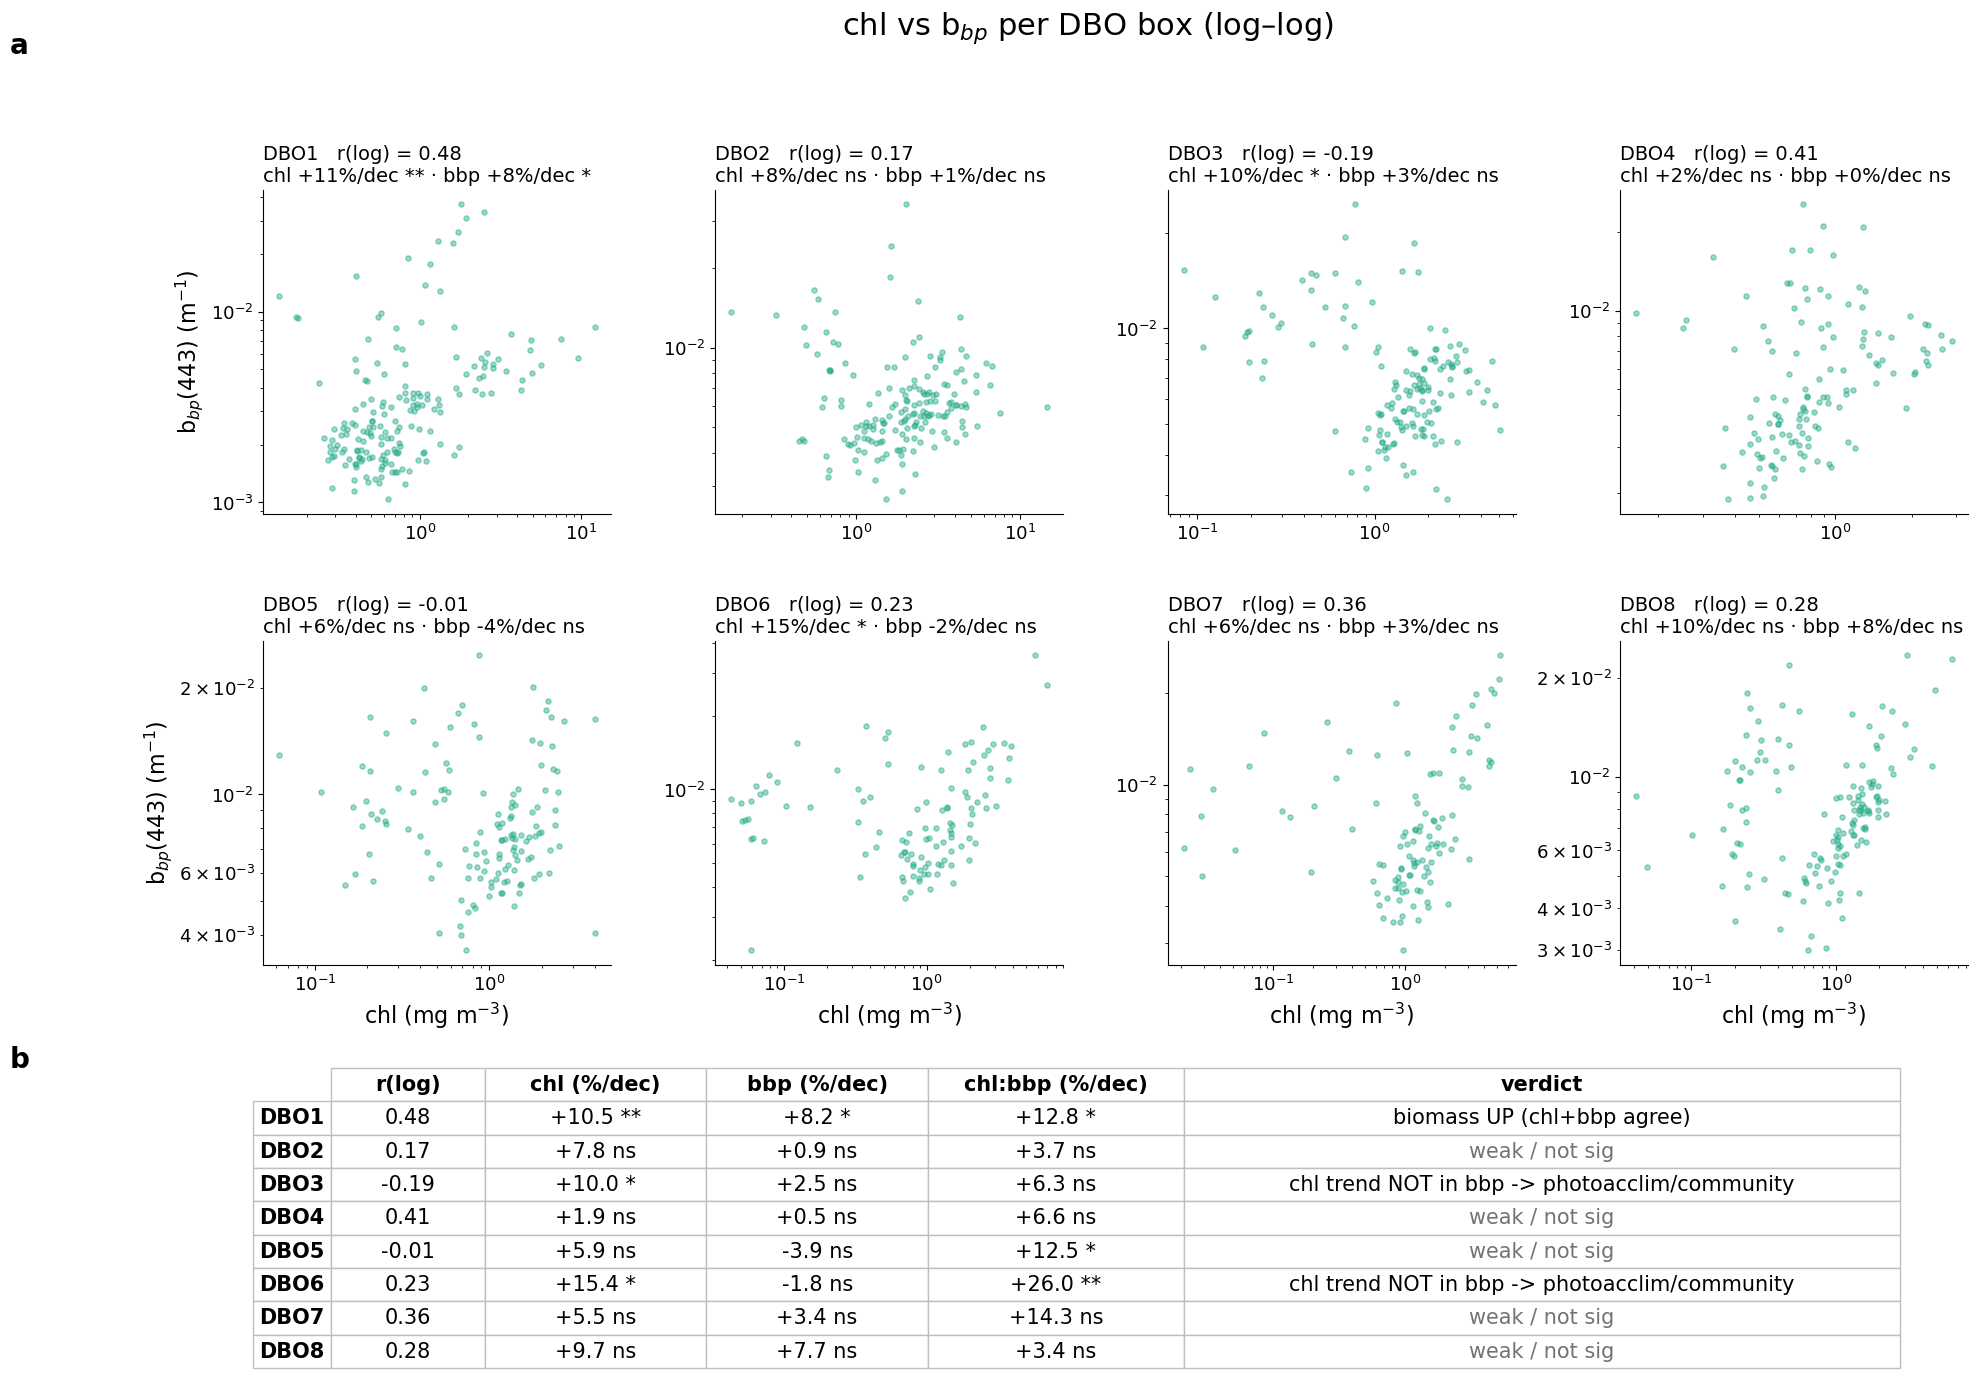

In [6]:
# --- fonts: one place to change them all ---
FS_SUP, FS_LETTER, FS_PANEL = 22, 20, 14      # suptitle, a/b letters, per-scatter titles
FS_AXLAB, FS_TICK, FS_TABLE = 16, 13, 15      # axis labels, tick labels, table text
SCAT_COLOR = "#2a8"

ncol = 4; nrow_sc = int(np.ceil(len(names) / ncol))
fig = plt.figure(figsize=(22, 5.2 * nrow_sc + 4.6))
gs = fig.add_gridspec(nrow_sc + 1, ncol, height_ratios=[1.0] * nrow_sc + [0.78],
                      hspace=0.42, wspace=0.30)

# ---- panel a: the 8 log-log scatters ----
for k, name in enumerate(names):
    ax = fig.add_subplot(gs[k // ncol, k % ncol])
    d = scatter_data[name]
    ax.scatter(d["c"], d["b"], s=14, alpha=0.45, color=SCAT_COLOR)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(f"{name}   r(log) = {d['r']:.2f}\n"
                 f"chl {d['ct']:+.0f}%/dec {_st(d['cp'])} · bbp {d['bt']:+.0f}%/dec {_st(d['bp'])}",
                 fontsize=FS_PANEL, loc="left")
    ax.tick_params(labelsize=FS_TICK, which="both")
    if k // ncol == nrow_sc - 1: ax.set_xlabel("chl (mg m$^{-3}$)", fontsize=FS_AXLAB)
    if k % ncol == 0:            ax.set_ylabel("b$_{bp}$(443) (m$^{-1}$)", fontsize=FS_AXLAB)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)

# ---- panel b: the verdict table ----
axt = fig.add_subplot(gs[nrow_sc, :]); axt.axis("off")
cols = ["r(log)", "chl (%/dec)", "bbp (%/dec)", "chl:bbp (%/dec)", "verdict"]
cells = [[f"{v['r(log chl,bbp)']:.2f}",
          f"{v['chl(%/dec)']:+.1f} {v['chl_sig']}",
          f"{v['bbp(%/dec)']:+.1f} {v['bbp_sig']}",
          f"{v['chl:bbp(%/dec)']:+.1f} {v['ratio_sig']}",
          v["verdict"]] for _, v in tbl.iterrows()]
table = axt.table(cellText=cells, rowLabels=list(tbl.index), colLabels=cols,
                  cellLoc="center", rowLoc="center", loc="center",
                  colWidths=[0.09, 0.13, 0.13, 0.15, 0.42])
table.auto_set_font_size(False); table.set_fontsize(FS_TABLE)
table.scale(1.0, 2.0)                                     # taller rows for the bigger type
for (ri, ci), cell in table.get_celld().items():
    cell.set_edgecolor("0.75")
    if ri == 0 or ci == -1: cell.set_text_props(fontweight="bold")
    if ri > 0 and "sig" not in cols[ci] and ci == 4:      # grey the null verdicts
        if "weak" in cells[ri - 1][4] or "n/a" in cells[ri - 1][4]:
            cell.set_text_props(color="0.45")

# ---- letters + title ----
fig.text(0.01, 0.985, "a", fontsize=FS_LETTER, fontweight="bold", va="top")
y_b = gs[nrow_sc, 0].get_position(fig).y1 + 0.012
fig.text(0.01, y_b, "b", fontsize=FS_LETTER, fontweight="bold", va="bottom")
fig.suptitle("chl vs b$_{bp}$ per DBO box (log–log)", fontsize=FS_SUP, x=0.5, y=1.0)

OUT = Path.home() / "ADD_YOUR_PATH" / "bbp" / "chl_vs_bbp_panel_figure"  # add your path
for ext in ("png", "pdf"):
    fig.savefig(f"{OUT}.{ext}", dpi=200, bbox_inches="tight")
    print("saved", f"{OUT}.{ext}")
plt.show()

### Reading it (from the source notebook)

- high r + chl & bbp trends **agree** → the chl change reflects a real particle/biomass change
- chl trends but bbp does **not** (and the chl:bbp ratio trend is significant) → pigment /
  photoacclimation or community shift, not biomass
- **Caveat (DBO shelf):** b$_{bp}$ also responds to non-algal particles (sediment resuspension in
  <50 m water), so on the shallow shelf high b$_{bp}$ is not purely phytoplankton — interpret the
  coastal boxes cautiously.

---

# Part B — Fig. S3: pre/post-2024 trend split (adg, Kd, bbp, SST)

*This part was a separate notebook before the repository was consolidated; it starts from its own imports and configuration, so it can be run on its own after the sections above.*

# MODIS **adg(443) / Kd(490) / bbp(443)** over DBO — pre/post-2024 trend split

Replicates the deseasonalized-anomaly **trend split pre/post 2024** (+ recent-tail sensitivity
and endpoint-leverage tests) already done for chl (`1_pull_data/01_modis-aoemp-chl-daily.ipynb` §15),
SST (`1_pull_data/06_modis-sst-daily.ipynb`) and cloud fraction (`2_figures/figS10_S11_clouds-and-valid-days.ipynb`), applied to the three
standard MODIS ocean-color products.

**Self-contained.** Loads the per-box time series straight from the streaming
checkpoints saved in `~` by the product notebooks (no earthaccess, no re-streaming):

| product | checkpoint (in `$HOME`) | cadence | source notebook |
|---|---|---|---|
| adg(443) — CDOM+detritus absorption | `modis_adg_dbo_8d_ckpt.pkl` | 8-day | `1_pull_data/04_modis-adg443-8day.ipynb` |
| Kd(490) — diffuse attenuation | `modis_kd490_dbo_8d_ckpt.pkl` | 8-day | `1_pull_data/05_modis-kd490-8day.ipynb` |
| bbp(443) — particulate backscatter | `modis_bbp_dbo_ckpt.pkl` | monthly | `1_pull_data/03_modis-bbp443-monthly.ipynb` |

Method (identical to the chl §15 analysis): log10 → full-record seasonal climatology
(DOY ±12 d window for 8-day products; month-of-year for monthly) → anomaly →
per-segment **Theil–Sen slope + AR(1)-adjusted Mann–Kendall p**, split at 2024, with an
AR(1)-inflated 95% CI band on significant segments.

> **Caveats.** Post-2024 is only ~1.5–2 yr — steep, wide-CI segments are expected; read them as
> "did the recent years depart from the long-term line", not as decadal rates. bbp is monthly, so the
> post-2024 segment has very few points (`SEG_MINN` is relaxed to 8 there); interpret accordingly.
> Ocean-color products also carry a possible PACE-era / reprocessing discontinuity — a step change at
> the split would also show up as two divergent segments.

## 1. Imports

In [1]:
import os, pickle, warnings
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import theilslopes, kendalltau, norm, t as tdist
warnings.filterwarnings("ignore", category=RuntimeWarning)
print("imports ok")

imports ok


## 2. Configuration — products, checkpoints, split year

Checkpoints are looked up in `$MODIS_CKPT_DIR` if set, else `$HOME`
(where the product notebooks saved them).

In [2]:
SPLIT        = 2024                       # segment boundary: years < SPLIT  vs  years >= SPLIT
CUTOFF       = SPLIT                      # recent-tail tests drop years >= CUTOFF
CLIM_HALFWIN = 12                         # DOY climatology half-window (days) for the 8-day products
SEG_MINN     = {"8D": 20, "MO": 8}        # min points per trend segment (monthly bbp is data-poor post-2024)
CKPT_DIR     = Path(os.environ.get("MODIS_CKPT_DIR", str(Path.home())))  # add your path
OUTDIR       = Path("outputs_trend_split"); OUTDIR.mkdir(exist_ok=True)

PRODUCTS = {
    "adg":   dict(ckpt=CKPT_DIR/"modis_adg_dbo_8d_ckpt.pkl",   cadence="8D",
                  label="adg(443)", unit="m$^{-1}$",
                  title="MODIS GIOP adg(443) — CDOM+detritus absorption, 8-day"),
    "kd490": dict(ckpt=CKPT_DIR/"modis_kd490_dbo_8d_ckpt.pkl", cadence="8D",
                  label="Kd(490)",  unit="m$^{-1}$",
                  title="MODIS Kd(490) — diffuse attenuation, 8-day"),
    "bbp":   dict(ckpt=CKPT_DIR/"modis_bbp_dbo_ckpt.pkl",      cadence="MO",
                  label="bbp(443)", unit="m$^{-1}$",
                  title="MODIS GIOP bbp(443) — particulate backscatter, monthly"),
}
for k, p in PRODUCTS.items():
    print(f"{k:6s} {'OK ' if p['ckpt'].exists() else 'MISSING '} {p['ckpt']}")

adg    OK  ~/modis_adg_dbo_8d_ckpt.pkl
kd490  OK  ~/modis_kd490_dbo_8d_ckpt.pkl
bbp    OK  ~/modis_bbp_dbo_ckpt.pkl


## 3. Load checkpoints → per-box series (+ Full DBO region)

Each checkpoint stores `box_rows = {date: {DBOn: box-mean value}}` from the streaming pass.
"Full DBO region" = unweighted mean of the box-mean series (same convention as the chl figure).

In [3]:
def load_box_series(ckpt_path):
    o = pickle.load(open(ckpt_path, "rb"))
    rows = o["box_rows"] if isinstance(o, dict) and "box_rows" in o else o
    dts = sorted(rows); t = np.array([np.datetime64(d.isoformat()) for d in dts])
    boxes = sorted({n for d in dts for n in rows[d]})
    return {n: xr.DataArray(np.array([rows[d].get(n, np.nan) for d in dts], float),
                            dims="time", coords={"time": t}) for n in boxes}

series = {}                                # {product: {"Full DBO region": da, "DBO1": da, ...}}
for k, p in PRODUCTS.items():
    if not p["ckpt"].exists():
        print(f"!! {k}: checkpoint missing — skipped ({p['ckpt']})"); continue
    box = load_box_series(p["ckpt"])
    t0 = next(iter(box.values()))["time"].values
    full = xr.DataArray(np.nanmean(np.stack([box[n].values for n in box]), axis=0),
                        dims="time", coords={"time": t0})
    series[k] = {"Full DBO region": full, **box}
    tt = pd.to_datetime(t0)
    print(f"{k:6s} {len(t0):5d} steps  {tt.min().date()} -> {tt.max().date()}  | boxes: {list(box)}")
assert series, "No checkpoints found - set MODIS_CKPT_DIR or copy the .pkl files into $HOME."


adg     1076 steps  2002-07-04 -> 2025-11-17  | boxes: ['DBO1', 'DBO2', 'DBO3', 'DBO4', 'DBO5', 'DBO6', 'DBO7', 'DBO8']
kd490   1076 steps  2002-07-04 -> 2025-11-17  | boxes: ['DBO1', 'DBO2', 'DBO3', 'DBO4', 'DBO5', 'DBO6', 'DBO7', 'DBO8']
bbp      257 steps  2002-07-01 -> 2025-10-01  | boxes: ['DBO1', 'DBO2', 'DBO3', 'DBO4', 'DBO5', 'DBO6', 'DBO7', 'DBO8']


## 4. Trend helpers

Verbatim from the chl §15 loader (`theilsen_mk_ar1`, `_lag1`, `_stars`, per-segment fitter),
with `deseasonalize_log10` generalized to the product cadence: DOY climatology (±`CLIM_HALFWIN` d,
circular) for 8-day products, month-of-year climatology for monthly. All three products are
positive-definite (m⁻¹), so the log10-anomaly recipe carries over unchanged and
%/decade = `(10**(slope*10)-1)*100` is directly comparable to the chl figure.

In [4]:
def _lag1(r):
    r = np.asarray(r, float); a, b = r[1:], r[:-1]; v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 10 else 0.0

def theilsen_mk_ar1(x, y, minn=8):
    v = np.isfinite(x) & np.isfinite(y); x, y = np.asarray(x)[v], np.asarray(y)[v]; n = len(x)
    if n < minn:
        return dict(slope=np.nan, intercept=np.nan, tau=np.nan, p_naive=np.nan, p_adj=np.nan, phi=np.nan, n=n)
    slope, intercept, _, _ = theilslopes(y, x)
    tau, p_naive = kendalltau(x, y)
    sl, ic = np.polyfit(x, y, 1); phi = _lag1(y - (sl * x + ic))
    n_eff = n * (1 - phi) / (1 + phi) if (abs(phi) < 1 and phi != 0) else n
    p_adj = 2 * (1 - norm.cdf(abs(tau / np.sqrt(2*(2*n_eff+5)/(9*n_eff*(n_eff-1)))))) if n_eff > 4 else np.nan
    return dict(slope=slope, intercept=intercept, tau=tau, p_naive=p_naive, p_adj=p_adj, phi=phi, n=n)

def _stars(p):
    return ("***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns") if np.isfinite(p) else "n/a"

def deseasonalize_log10(da, cadence):
    raw = np.asarray(da.values, float).copy(); raw[~np.isfinite(raw) | (raw <= 0)] = np.nan
    y = np.log10(raw); t = pd.to_datetime(da["time"].values)
    if cadence == "MO":                                        # month-of-year climatology
        mo = np.asarray(t.month, int); clim = np.full(13, np.nan)
        for m in range(1, 13):
            v = (mo == m) & np.isfinite(y)
            if v.sum() >= 5: clim[m] = np.nanmean(y[v])
        anom = y - clim[mo]
    else:                                                      # 8D: circular DOY climatology
        doy = np.asarray(t.dayofyear, int); clim = np.full(367, np.nan)
        for d in range(1, 367):
            dd = np.abs(doy - d); dd = np.minimum(dd, 366 - dd)
            m = (dd <= CLIM_HALFWIN) & np.isfinite(y)
            if m.sum() >= 5: clim[d] = np.nanmean(y[m])
        anom = y - clim[doy]
    dec = np.asarray(t.year + (np.asarray(t.dayofyear) - 1) / 365.25, float)
    return t, dec, anom

def _seg_trend(x, y, minn):
    """Per-segment Theil-Sen trend (+ %/dec) with an AR(1)-inflated CI band."""
    v = np.isfinite(x) & np.isfinite(y); x, y = np.asarray(x)[v], np.asarray(y)[v]; n = len(x)
    if n < minn: return None
    r  = theilsen_mk_ar1(x, y, minn=minn)
    sl, ic, p = r["slope"], r["intercept"], r["p_adj"]
    resid = y - (sl * x + ic); phi = _lag1(resid)
    ne    = n * (1 - phi) / (1 + phi) if (abs(phi) < 1 and phi != 0) else n
    ne    = float(max(min(ne, n), 3))
    xbar  = x.mean(); Sxx = np.sum((x - xbar) ** 2)
    s2adj = (np.sum(resid ** 2) / max(n - 2, 1)) * (n / ne)
    return dict(slope=sl, intercept=ic, p=p, pct=(10 ** (sl * 10) - 1) * 100,
                line_se=lambda xx: np.sqrt(s2adj * (1.0 / n + (xx - xbar) ** 2 / Sxx)),
                dof=max(ne - 2, 1), xmin=x.min(), xmax=x.max(), n=n)

SIG_UP, SIG_DOWN, NS = "#d6604d", "#2166ac", "0.55"            # coral = increase, blue = decrease
def _style(sl, p):
    if np.isfinite(p) and p < 0.05:
        return (SIG_UP if sl > 0 else SIG_DOWN), "-", 2.3, True
    return NS, "--", 1.8, False
print("helpers ready: theilsen_mk_ar1, deseasonalize_log10, _seg_trend, _stars")

helpers ready: theilsen_mk_ar1, deseasonalize_log10, _seg_trend, _stars


## 5. Per-box trends, full record vs. pre-2024 (adg, Kd, bbp; same recipe as the cloud and SST splits) — Fig. S3

  cloudfrac  modis_cloudfraction_products.pkl  8,772 steps | 2002-07-04 -> 2026-08-10
  sst        box_ts_portable.pkl         8,717 steps | 2002-07-04 -> 2026-06-09


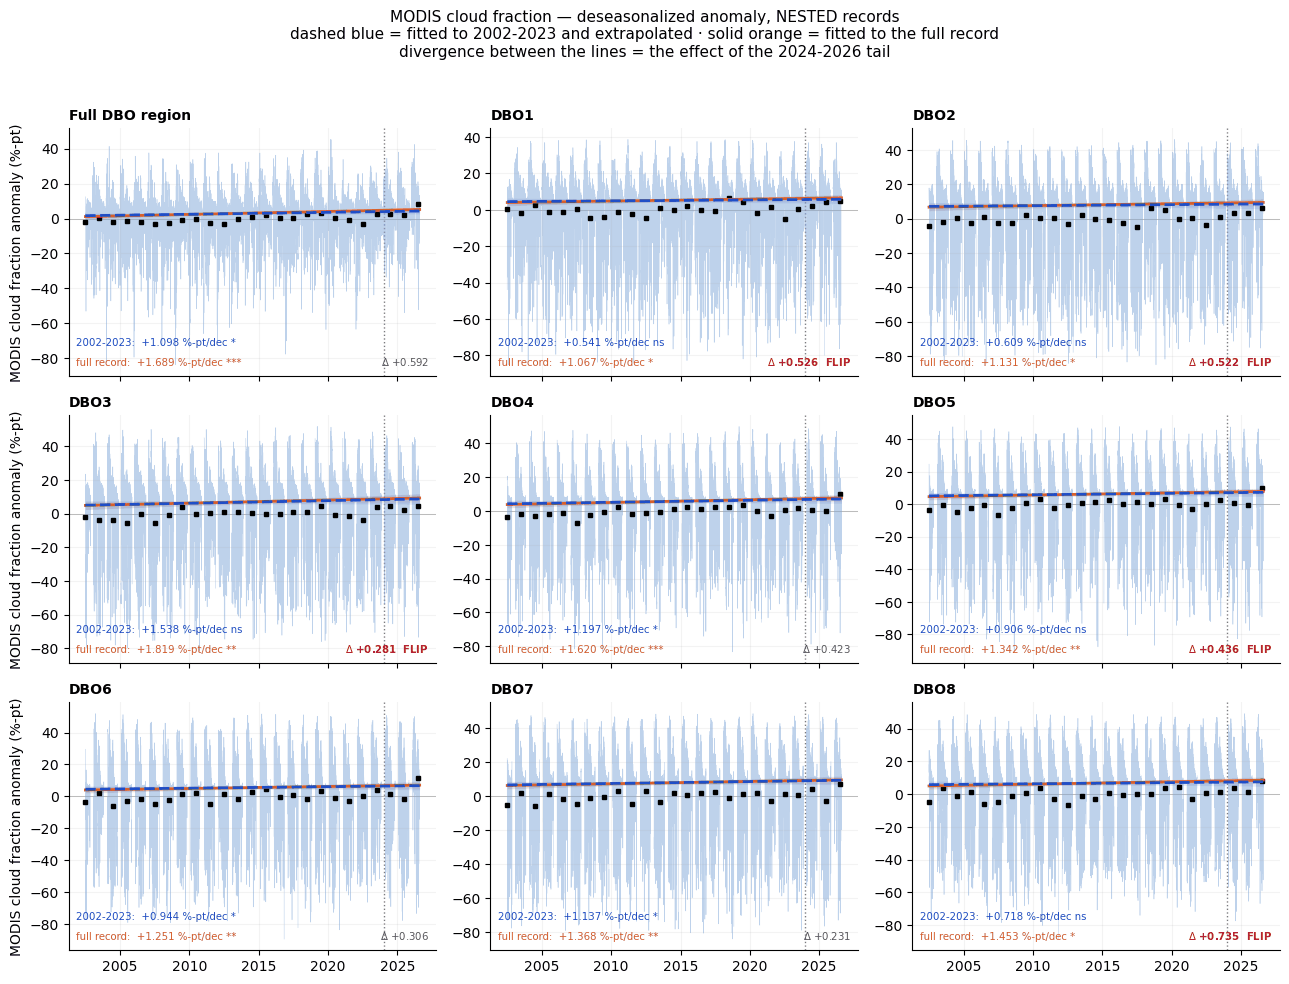


=== MODIS cloud fraction — 2002-2023 vs full record (%-pt/decade) ===
                 perdec<2024  p<2024  perdec_full  p_full   delta   flip
box                                                                     
Full DBO region       1.0979  0.0124       1.6895  0.0000  0.5916  False
DBO1                  0.5409  0.2967       1.0666  0.0134  0.5256   True
DBO2                  0.6091  0.3299       1.1314  0.0319  0.5224   True
DBO3                  1.5380  0.0671       1.8192  0.0082  0.2812   True
DBO4                  1.1970  0.0266       1.6203  0.0008  0.4233  False
DBO5                  0.9063  0.0987       1.3419  0.0063  0.4356   True
DBO6                  0.9441  0.0394       1.2505  0.0030  0.3064  False
DBO7                  1.1366  0.0479       1.3675  0.0075  0.2310  False
DBO8                  0.7182  0.3331       1.4534  0.0244  0.7352   True
significance FLIPS: ['DBO1', 'DBO2', 'DBO3', 'DBO5', 'DBO8']


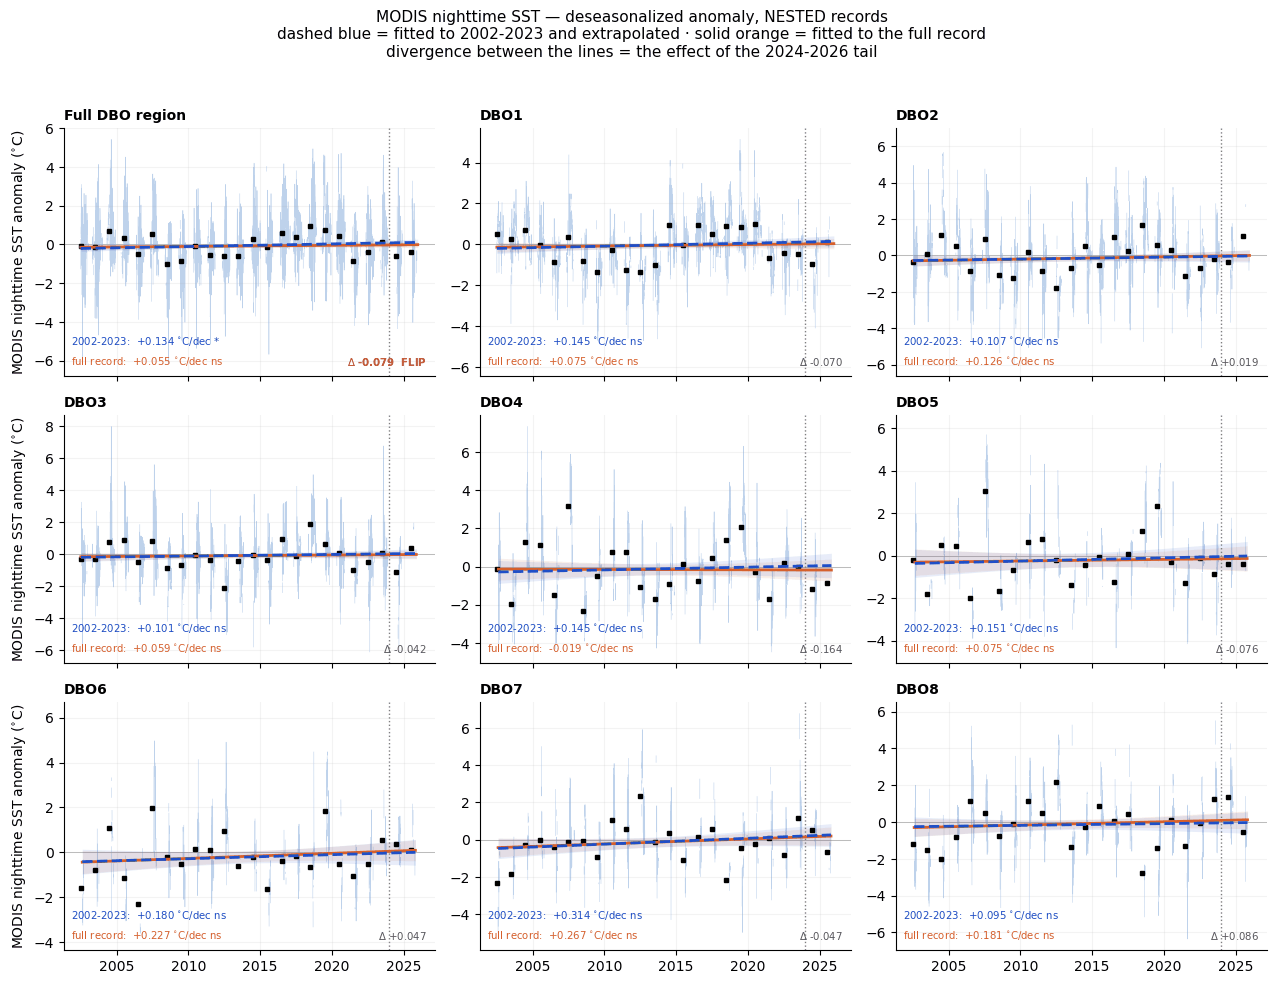


=== MODIS nighttime SST — 2002-2023 vs full record ($^{\circ}$C/decade) ===
                 perdec<2024  p<2024  perdec_full  p_full   delta   flip
box                                                                     
Full DBO region       0.1336  0.0148       0.0548  0.2704 -0.0788   True
DBO1                  0.1453  0.1349       0.0751  0.4098 -0.0702  False
DBO2                  0.1072  0.3371       0.1265  0.2195  0.0193  False
DBO3                  0.1005  0.2545       0.0588  0.4796 -0.0418  False
DBO4                  0.1449  0.5451      -0.0194  0.9270 -0.1644  False
DBO5                  0.1508  0.5468       0.0749  0.7251 -0.0758  False
DBO6                  0.1803  0.3974       0.2268  0.2049  0.0465  False
DBO7                  0.3143  0.1324       0.2671  0.1231 -0.0472  False
DBO8                  0.0954  0.6400       0.1815  0.2976  0.0860  False
significance FLIPS: ['Full DBO region']


In [9]:
# ============================================================================
# NESTED-RECORD COMPARISON for the two NON-Rrs controls: cloud fraction and SST
#
#   solid orange = fitted to the full record
#   dashed blue  = fitted to 2002-2023 only, then extrapolated across the span
#
# Self-contained: loads straight from the checkpoints, defines its own helpers.
# Anomalies are LINEAR here (not log10) because SST can be negative and cloud
# fraction is already a percentage, so trends are in native units per decade
# (degC/dec, %-points/dec) rather than %/dec.
# ============================================================================
import os, pickle
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from scipy.stats import theilslopes, kendalltau, norm, t as tdist

CKPT_DIR     = Path(os.environ.get("MODIS_CKPT_DIR", str(Path.home())))  # add your path
CUTOFF_N     = 2024        # "early" fit uses years < CUTOFF_N
CLIM_HALFWIN = 12          # matches the optical notebooks
MINN         = 20          # min points per fit
SEASON       = None        # None = all months; (5,6,7,8,9) = open-water only
C_FULL, C_EARLY = "#d6602c", "#1f4ec7"

OUTDIR2 = Path.cwd() / "outputs_controls"; OUTDIR2.mkdir(exist_ok=True)

CONTROLS = {
    "cloudfrac": dict(label="MODIS cloud fraction", unit="%-pt", scale=100.0,
                      paths=[CKPT_DIR / "modis_cloudfraction_products.pkl",
                             CKPT_DIR / "modis_cloudfraction_ckpt.pkl"]),
    "sst":       dict(label="MODIS nighttime SST", unit="$^{\\circ}$C", scale=1.0,
                      paths=[CKPT_DIR / "box_ts_portable.pkl",
                             CKPT_DIR / "outputs_MODIS_SST" / "box_ts_portable.pkl",
                             Path.home() / "ADD_YOUR_PATH" / "modis" /  # add your path
                             "outputs_MODIS_SST" / "box_ts_portable.pkl"]),
}

# ---- loaders (same structure-sniffing as the other post-2024 notebooks) -----
def _as_da(v):
    if isinstance(v, xr.DataArray): return v
    if isinstance(v, xr.Dataset):
        for k in ("daily_mean", "mean", "value"):
            if k in v: return v[k]
        return v[list(v.data_vars)[0]]
    if isinstance(v, dict):
        if "time" in v:
            for k in ("daily_mean", "mean", "value"):
                if k in v:
                    return xr.DataArray(np.asarray(v[k], float), dims="time",
                                        coords={"time": np.asarray(v["time"])})
        for k in ("daily_mean", "mean", "value"):
            if k in v: return _as_da(v[k])
    raise TypeError(f"cannot coerce {type(v).__name__}")

def _keys_are_dates(d):
    import datetime as _dt
    ks = list(d)[:5]
    return bool(ks) and all(isinstance(k, (_dt.date, _dt.datetime, pd.Timestamp,
                                           np.datetime64)) for k in ks)

def _rows_to_series(rows, pick=0):
    dts = sorted(rows)
    if not dts: return {}
    def _slot(d):
        v = rows[d]
        return v[pick] if isinstance(v, (tuple, list)) else v
    boxes = sorted({n for d in dts for n in _slot(d)})
    t = np.array([np.datetime64(pd.Timestamp(d).to_pydatetime().isoformat()) for d in dts])
    return {n: xr.DataArray(np.array([float(_slot(d).get(n, np.nan)) for d in dts], float),
                            dims="time", coords={"time": t}) for n in boxes}

def _load_any(path, scale=1.0):
    obj = pickle.load(open(path, "rb"))
    if isinstance(obj, dict):
        if "box_ts" in obj:
            return {n: _as_da(v) * scale for n, v in obj["box_ts"].items()}
        for key in ("box_rows", "chl_rows", "rows"):
            if key in obj and isinstance(obj[key], dict) and obj[key]:
                return {n: s * scale for n, s in _rows_to_series(obj[key]).items()}
        vals = list(obj.values())
        if vals and all(isinstance(v, (xr.DataArray, xr.Dataset)) for v in vals):
            return {n: _as_da(v) * scale for n, v in obj.items()}
        if vals and isinstance(vals[0], dict) and ("time" in vals[0] or "daily_mean" in vals[0]):
            return {n: _as_da(v) * scale for n, v in obj.items()}
        if vals and _keys_are_dates(obj):
            return {n: s * scale for n, s in _rows_to_series(obj).items()}
    raise ValueError(f"unrecognised structure in {path.name}")

ctl_series = {}
for key, cfg in CONTROLS.items():
    for cand in cfg["paths"]:
        if Path(cand).exists():
            try:
                ctl_series[key] = _load_any(Path(cand), cfg["scale"])
                tt = pd.to_datetime(next(iter(ctl_series[key].values()))["time"].values)
                print(f"  {key:10s} {Path(cand).name:26s} {len(tt):6,d} steps | "
                      f"{tt.min().date()} -> {tt.max().date()}")
                break
            except Exception as exc:
                print(f"  {key}: {Path(cand).name} unreadable ({type(exc).__name__})")
    else:
        print(f"  {key}: MISSING -- tried {[str(x) for x in cfg['paths']]}")

REGION = "Full DBO region"
for key, boxes in ctl_series.items():
    names = sorted(n for n in boxes if n.upper().startswith("DBO"))
    al = xr.align(*[boxes[n] for n in names], join="outer")
    boxes[REGION] = xr.DataArray(np.nanmean(np.stack([a.values.astype(float) for a in al]), 0),
                                 dims="time", coords={"time": al[0]["time"].values})

# ---- stats: LINEAR anomalies, native units per decade -----------------------
def _lag1(r):
    r = np.asarray(r, float); a, b = r[1:], r[:-1]
    v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 10 else 0.0

def deseasonalize_linear(da, season=SEASON):
    """Value minus a smoothed circular day-of-year climatology (no log transform)."""
    y = np.asarray(da.values, float).copy()
    t = pd.to_datetime(da["time"].values)
    if season is not None:
        keep = np.isin(t.month, list(season)); y, t = y[keep], t[keep]
    y[~np.isfinite(y)] = np.nan
    doy = np.asarray(t.dayofyear, int)
    clim = np.full(367, np.nan)
    for d in range(1, 367):
        dd = np.abs(doy - d); dd = np.minimum(dd, 366 - dd)
        m = (dd <= CLIM_HALFWIN) & np.isfinite(y)
        if m.sum() >= 5: clim[d] = np.nanmean(y[m])
    return t, np.asarray(t.year + (doy - 1) / 365.25, float), y - clim[doy]

def _seg_trend_lin(x, y, minn=MINN):
    """Theil-Sen slope in units/decade + AR(1)-adjusted MK p + CI-band machinery."""
    v = np.isfinite(x) & np.isfinite(y); x, y = np.asarray(x)[v], np.asarray(y)[v]
    n = len(x)
    if n < minn: return None
    sl, ic, _, _ = theilslopes(y, x)
    tau, _ = kendalltau(x, y)
    a, b = np.polyfit(x, y, 1); phi = _lag1(y - (a * x + b))
    ne = n * (1 - phi) / (1 + phi) if (0 < phi < 1) else n
    ne = float(np.clip(ne, 3, n))
    p = 2 * (1 - norm.cdf(abs(tau / np.sqrt(2 * (2*ne + 5) / (9*ne*(ne - 1)))))) if ne > 4 else np.nan
    resid = y - (sl * x + ic)
    xbar = x.mean(); Sxx = float(np.sum((x - xbar) ** 2))
    s2adj = (np.sum(resid ** 2) / max(n - 2, 1)) * (n / ne)
    return dict(slope=sl, intercept=ic, p=p, per_dec=sl * 10, n=n,
                line_se=lambda xx: np.sqrt(s2adj * (1.0 / n + (xx - xbar) ** 2 / Sxx)),
                dof=max(ne - 2, 1))

def _st(p):
    if not np.isfinite(p): return "n/a"
    return "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "ns"

# ---- figure -----------------------------------------------------------------
ctl_tables = {}

def nested_control_figure(key):
    cfg = CONTROLS[key]; panels = ctl_series[key]
    names = [REGION] + sorted(n for n in panels if n.upper().startswith("DBO"))
    ncol = 3; nrow = int(np.ceil(len(names) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(13, 3.2 * nrow), sharex=True)
    axes = np.atleast_1d(axes).ravel(); rows = []

    for ax, name in zip(axes, names):
        t, dec, anom = deseasonalize_linear(panels[name])
        ax.plot(dec, anom, "-", color="#7ea6d8", lw=0.4, alpha=0.5, zorder=1)
        dfa = pd.DataFrame({"y": anom, "yr": np.asarray(t.year, int)}).dropna()
        if len(dfa):
            ga = dfa.groupby("yr")["y"].mean()
            ax.plot(ga.index.values + 0.5, ga.values, "s", color="k", ms=3.0, zorder=3)
        ax.axhline(0, color="0.7", lw=0.6, zorder=0)
        ax.axvline(CUTOFF_N, color="0.5", ls=":", lw=1.0, zorder=0)

        ok = np.isfinite(dec) & np.isfinite(anom)
        if ok.sum() < MINN:
            ax.set_title(name, loc="left", fontweight="bold", fontsize=10); continue
        xs = np.linspace(np.nanmin(dec[ok]), np.nanmax(dec[ok]), 200)

        info = {}
        for tag, sel, col, ls in (("full",  ok,                    C_FULL,  "-"),
                                  ("early", ok & (dec < CUTOFF_N), C_EARLY, "--")):
            r = _seg_trend_lin(dec[sel], anom[sel])
            if r is None:
                info[tag] = dict(txt=f"n<{MINN}", col="0.6", per_dec=np.nan, p=np.nan); continue
            yp = r["intercept"] + r["slope"] * xs
            band = tdist.ppf(0.975, r["dof"]) * r["line_se"](xs)
            ax.fill_between(xs, yp - band, yp + band, color=col, alpha=0.10, lw=0, zorder=2)
            ax.plot(xs, yp, ls=ls, color=col, lw=2.0, zorder=4)
            info[tag] = dict(txt=f"{r['per_dec']:+.3f} {cfg['unit']}/dec {_st(r['p'])}",
                             col=col, per_dec=r["per_dec"], p=r["p"])

        d = info["full"]["per_dec"] - info["early"]["per_dec"]
        flip = (np.isfinite(info["full"]["p"]) and np.isfinite(info["early"]["p"])
                and (info["full"]["p"] < 0.05) != (info["early"]["p"] < 0.05))
        rows.append((name, info["early"]["per_dec"], info["early"]["p"],
                     info["full"]["per_dec"], info["full"]["p"], d, flip))

        ax.set_title(name, loc="left", fontweight="bold", fontsize=10)
        ax.text(0.02, 0.115, f"2002-{CUTOFF_N-1}:  {info['early']['txt']}",
                transform=ax.transAxes, fontsize=7.3, color=info["early"]["col"],
                va="bottom", ha="left")
        ax.text(0.02, 0.035, f"full record:  {info['full']['txt']}",
                transform=ax.transAxes, fontsize=7.3, color=info["full"]["col"],
                va="bottom", ha="left")
        if np.isfinite(d):
            ax.text(0.98, 0.035, f"$\\Delta$ {d:+.3f}" + ("  FLIP" if flip else ""),
                    transform=ax.transAxes, fontsize=7.3,
                    color="#b2182b" if flip else "0.35",
                    fontweight="bold" if flip else "normal", va="bottom", ha="right")
        for spn in ("top", "right"): ax.spines[spn].set_visible(False)
        ax.grid(alpha=0.15)

    for ax in axes[len(names):]: ax.axis("off")
    for ax in axes[::ncol]: ax.set_ylabel(f"{cfg['label']} anomaly ({cfg['unit']})")
    fig.suptitle(f"{cfg['label']} — deseasonalized anomaly, NESTED records\n"
                 f"dashed blue = fitted to 2002-{CUTOFF_N-1} and extrapolated · "
                 "solid orange = fitted to the full record\n"
                 "divergence between the lines = the effect of the 2024-2026 tail",
                 fontsize=11, y=1.02)
    plt.tight_layout()
    fig.savefig(OUTDIR2 / f"{key}_nested_{CUTOFF_N}.png", dpi=150, bbox_inches="tight")
    plt.show()

    tbl = pd.DataFrame(rows, columns=["box", f"perdec<{CUTOFF_N}", f"p<{CUTOFF_N}",
                                      "perdec_full", "p_full", "delta", "flip"]).set_index("box")
    ctl_tables[key] = tbl
    print(f"\n=== {cfg['label']} — 2002-{CUTOFF_N-1} vs full record ({cfg['unit']}/decade) ===")
    print(tbl.round(4))
    print(f"significance FLIPS: {list(tbl.index[tbl['flip']]) or 'none'}")
    return tbl

for key in list(ctl_series):
    nested_control_figure(key)


## 6. Why the SST record responds later — SST pre/post split alongside (Fig. S3)

sst / Full DBO region: 3,806 valid obs | 22 pre-2024 years, 2 post-2024 years


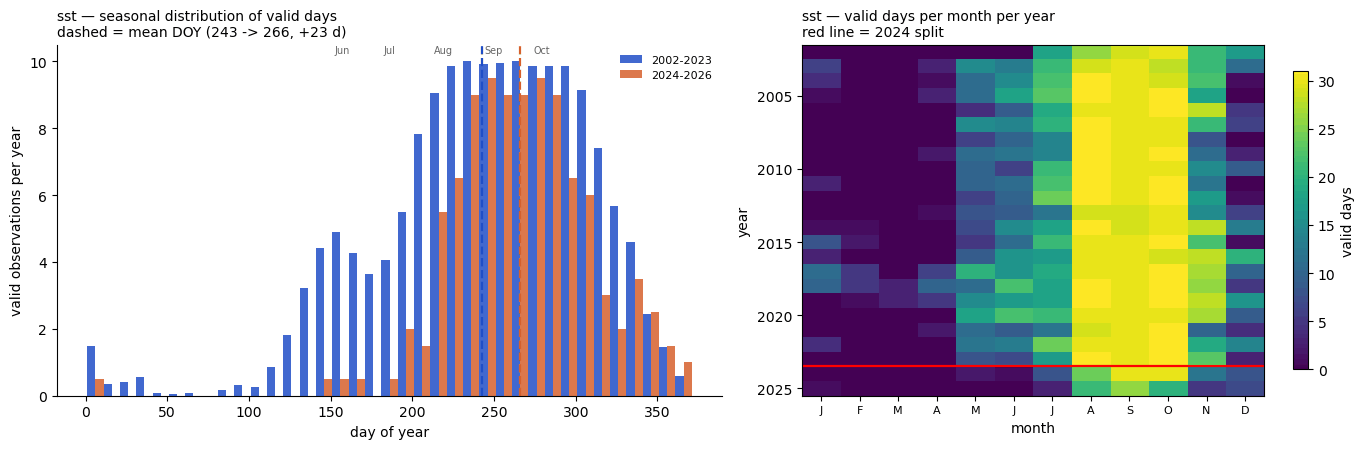


seasonal share of valid observations
                     Jun-Jul    Aug-Sep    other
  2002-2023         19.1%      36.6%     44.2%
  2024-2026          6.1%      51.0%     42.9%

valid days per year by month (last 10 years)
mo    Jan  Feb  Mar  Apr  May  Jun  Jul  Aug  Sep  Oct  Nov  Dec
yr                                                              
2016    3    0    0    0    9   16   17   30   30   29   28   20
2017   11    5    0    6   20   16   19   30   30   31   27   10
2018   10    5    3   10   11   22   18   31   30   31   26    5
2019    0    1    3    5   15   17   18   31   30   31   28   16
2020    0    0    0    0   18   22   21   30   30   30   27    9
2021    0    0    0    2   11    9   12   29   30   31   10    4
2022    4    0    0    0   12   13   24   30   30   31   19   14
2023    0    0    0    0    8    7   17   31   30   31   23    3
2024    0    0    0    0    2    1    8   24   30   30   12    8
2025    1    0    0    0    0    0    3   21   26   20    

In [11]:
# ============================================================================
# WHY IS POST-2024 SST 24 DAYS LATER?  -- where in the season did the data go?
#
# Counts VALID observations by day-of-year, pre-2024 vs post-2024, normalised
# per year so the two periods are comparable. If the mean shifted later because
# early/mid-season retrievals were lost, the post-2024 curve will collapse over
# Jun-Jul and hold over Aug-Sep. If the loss is spread evenly across the season,
# the cause is something else (QC / processing), not the nighttime-overpass idea.
#
# Needs `ctl_series` from the nested-controls cell. Set DIAG_KEY = "cloudfrac"
# to run the same diagnostic on the control that did NOT shift.
# ============================================================================
DIAG_KEY  = "sst"                  # "sst" | "cloudfrac"
DIAG_BOX  = "Full DBO region"
CUT       = 2024
BINW      = 10                     # day-of-year bin width

assert "ctl_series" in globals() and DIAG_KEY in ctl_series, \
    "run the nested-controls cell first (it defines ctl_series)"

import numpy as np, pandas as pd, matplotlib.pyplot as plt

da   = ctl_series[DIAG_KEY][DIAG_BOX]
vals = np.asarray(da.values, float)
t    = pd.to_datetime(da["time"].values)
ok   = np.isfinite(vals)
yr   = np.asarray(t.year, int)[ok]
doy  = np.asarray(t.dayofyear, int)[ok]
mon  = np.asarray(t.month, int)[ok]

pre, post = yr < CUT, yr >= CUT
n_pre_yr  = len(np.unique(yr[pre]))
n_post_yr = len(np.unique(yr[post]))
print(f"{DIAG_KEY} / {DIAG_BOX}: {ok.sum():,} valid obs | "
      f"{n_pre_yr} pre-{CUT} years, {n_post_yr} post-{CUT} years")

bins   = np.arange(1, 367 + BINW, BINW)
ctr    = bins[:-1] + BINW / 2
h_pre  = np.histogram(doy[pre],  bins=bins)[0] / max(n_pre_yr, 1)
h_post = np.histogram(doy[post], bins=bins)[0] / max(n_post_yr, 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6),
                               gridspec_kw={"width_ratios": [1.15, 1]})

# ---- left: seasonal distribution of valid days ------------------------------
ax1.bar(ctr - BINW/4, h_pre,  BINW/2, color="#1f4ec7", alpha=.85, label=f"2002-{CUT-1}")
ax1.bar(ctr + BINW/4, h_post, BINW/2, color="#d6602c", alpha=.85, label=f"{CUT}-2026")
ax1.axvline(np.average(doy[pre]),  color="#1f4ec7", ls="--", lw=1.6)
ax1.axvline(np.average(doy[post]), color="#d6602c", ls="--", lw=1.6)
for m, lab in zip([152, 182, 213, 244, 274], ["Jun", "Jul", "Aug", "Sep", "Oct"]):
    ax1.text(m, ax1.get_ylim()[1], lab, fontsize=7, color="0.4", va="top", ha="left")
ax1.set_xlabel("day of year"); ax1.set_ylabel("valid observations per year")
ax1.set_title(f"{DIAG_KEY} — seasonal distribution of valid days\n"
              f"dashed = mean DOY ({np.average(doy[pre]):.0f} -> {np.average(doy[post]):.0f}, "
              f"{np.average(doy[post]) - np.average(doy[pre]):+.0f} d)",
              fontsize=10, loc="left")
ax1.legend(frameon=False, fontsize=8)
for s in ("top", "right"): ax1.spines[s].set_visible(False)

# ---- right: year x month count matrix ---------------------------------------
cm = (pd.DataFrame({"yr": yr, "mo": mon})
        .groupby(["yr", "mo"]).size().unstack(fill_value=0)
        .reindex(columns=range(1, 13), fill_value=0))
im = ax2.imshow(cm.values, aspect="auto", cmap="viridis",
                extent=[0.5, 12.5, cm.index.max() + .5, cm.index.min() - .5])
ax2.axhline(CUT - 0.5, color="red", lw=1.6)
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(["J","F","M","A","M","J","J","A","S","O","N","D"], fontsize=8)
ax2.set_ylabel("year"); ax2.set_xlabel("month")
ax2.set_title(f"{DIAG_KEY} — valid days per month per year\nred line = {CUT} split",
              fontsize=10, loc="left")
plt.colorbar(im, ax=ax2, shrink=.85, label="valid days")
plt.tight_layout(); plt.show()

# ---- the decisive numbers ---------------------------------------------------
def _share(sel, months):
    tot = sel.sum()
    return 100 * np.isin(mon[sel], months).sum() / tot if tot else np.nan

print(f"\nseasonal share of valid observations")
print(f"                     Jun-Jul    Aug-Sep    other")
for lab, sel in ((f"2002-{CUT-1}", pre), (f"{CUT}-2026", post)):
    print(f"  {lab:11s}      {_share(sel,[6,7]):5.1f}%     "
          f"{_share(sel,[8,9]):5.1f}%    {_share(sel,[1,2,3,4,5,10,11,12]):5.1f}%")

print(f"\nvalid days per year by month (last {min(10, len(cm))} years)")
print(cm.tail(10).rename(columns={i: m for i, m in enumerate(
    ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], 1)}).to_string())

jj_pre, jj_post = _share(pre, [6, 7]), _share(post, [6, 7])
print(f"\nVERDICT")
if np.isfinite(jj_pre) and np.isfinite(jj_post) and jj_post < 0.6 * jj_pre:
    print(f"  Jun-Jul share fell {jj_pre:.1f}% -> {jj_post:.1f}% -- early/mid-season retrievals")
    print("  were LOST. Consistent with the nighttime-overpass explanation.")
elif np.isfinite(jj_pre) and np.isfinite(jj_post) and jj_post > 1.4 * jj_pre:
    print(f"  Jun-Jul share ROSE {jj_pre:.1f}% -> {jj_post:.1f}% -- the shift is not an")
    print("  early-season loss; look elsewhere.")
else:
    print(f"  Jun-Jul share roughly unchanged ({jj_pre:.1f}% -> {jj_post:.1f}%) -- the loss is")
    print("  spread across the season, so QC/processing is the likelier cause, not overpass timing.")


---

# Part C — Fig. S13: tail-end sensitivity with significance stars

*This part was a separate notebook before the repository was consolidated; it starts from its own imports and configuration, so it can be run on its own after the sections above.*

# Tail-sensitivity bars **with significance stars** — AO.emp chl / adg(443) / Kd(490) / bbp(443)

Remake of the "Sensitivity of the per-box trend to the 2024–2026 tail" figure from
`2_figures/figS02_S03_S13_product-record-checks.ipynb` §6, with two changes:

1. **A fourth panel: Lewis & Arrigo AO.emp chlorophyll** (daily), loaded from the
   `modis_LA_dbo_DAY_v2_ckpt.pkl` checkpoint — key **`chl_rows_e`**, which is the AO.emp series
   (`chl_rows` is the AOReg.emp variant; see the note in §3).
2. **AR(1)-adjusted Mann–Kendall significance drawn on the bars** (`*` p<0.05, `**` p<0.01,
   `***` p<0.001, unmarked = ns), so the figure stands alone without a supplementary table.

**Self-contained.** Loads the per-box series straight from the streaming
checkpoints in `$HOME` (or `$MODIS_CKPT_DIR`); no earthaccess, no re-streaming. Estimator,
climatology, and %/decade conversion are byte-for-byte the source notebook's, so the adg/Kd/bbp
bars are identical to the original figure — only the chl panel and the stars are new.

| panel | product | checkpoint | cadence |
|---|---|---|---|
| a | AO.emp chl | `modis_LA_dbo_DAY_v2_ckpt.pkl` (`chl_rows_e`) | daily |
| b | adg(443) | `modis_adg_dbo_8d_ckpt.pkl` | 8-day |
| c | Kd(490) | `modis_kd490_dbo_8d_ckpt.pkl` | 8-day |
| d | bbp(443) | `modis_bbp_dbo_ckpt.pkl` | monthly |

## 1. Imports

In [1]:
import os, pickle, warnings
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import theilslopes, kendalltau, norm
warnings.filterwarnings("ignore", category=RuntimeWarning)
print("imports ok")

imports ok


## 2. Configuration — verbatim from the trend-split notebook, plus the chl entry

In [2]:
CUTOFF       = 2024                       # "early" fit uses years < CUTOFF
CLIM_HALFWIN = 12                         # DOY climatology half-window (days), daily + 8-day products
SEG_MINN     = {"DAY": 20, "8D": 20, "MO": 8}   # min points per fit (monthly bbp is data-poor)
SIG_LEVELS   = "(* p<0.05 · ** p<0.01 · *** p<0.001 · unmarked = ns)"
CKPT_DIR     = Path(os.environ.get("MODIS_CKPT_DIR", str(Path.home())))  # add your path
OUTDIR       = Path("outputs_trend_split"); OUTDIR.mkdir(exist_ok=True)

# panel order, top to bottom
PRODUCTS = {
    "chl":   dict(ckpt=CKPT_DIR/"modis_LA_dbo_DAY_v2_ckpt.pkl", cadence="DAY",
                  key="chl_rows_e", ext=CKPT_DIR/"prepost_ext_chl_AOemp.pkl",
                  label="AO.emp chl", letter="a"),
    "adg":   dict(ckpt=CKPT_DIR/"modis_adg_dbo_8d_ckpt.pkl",   cadence="8D",
                  key="box_rows", ext=None, label="adg(443)", letter="b"),
    "kd490": dict(ckpt=CKPT_DIR/"modis_kd490_dbo_8d_ckpt.pkl", cadence="8D",
                  key="box_rows", ext=None, label="Kd(490)",  letter="c"),
    "bbp":   dict(ckpt=CKPT_DIR/"modis_bbp_dbo_ckpt.pkl",      cadence="MO",
                  key="box_rows", ext=None, label="bbp(443)", letter="d"),
}
for k, p in PRODUCTS.items():
    print(f"{k:6s} {'OK ' if p['ckpt'].exists() else 'MISSING '} {p['ckpt']}")

chl    OK  ~/modis_LA_dbo_DAY_v2_ckpt.pkl
adg    OK  ~/modis_adg_dbo_8d_ckpt.pkl
kd490  OK  ~/modis_kd490_dbo_8d_ckpt.pkl
bbp    OK  ~/modis_bbp_dbo_ckpt.pkl


## 3. Load checkpoints → per-box series (+ Full DBO region)

Same loader as the trend-split notebook, generalised to take the pickle key per product and to
merge the chl 2026 extension when present.

> **Which chl is which.** The Lewis & Arrigo checkpoint holds two series: `chl_rows` (AOReg.emp,
> the regional variant) and `chl_rows_e` (**AO.emp** — the algorithm the scorecard uses). This
> notebook uses `chl_rows_e`. ⚠ The nested-record chl figure in the trend-split notebook (its
> cell "adding chl") loaded `chl_rows` while titling the figure AO.emp — if the chl bars here
> differ noticeably from that figure's fits, this is why, and *this* notebook is the
> correctly-labelled one.

In [3]:
def _rows_to_das(rows):
    dts = sorted(rows); t = np.array([np.datetime64(pd.Timestamp(d).to_pydatetime().isoformat())
                                      for d in dts])
    boxes = sorted({n for d in dts for n in rows[d]})
    return {n: xr.DataArray(np.array([float(rows[d].get(n, np.nan)) for d in dts], float),
                            dims="time", coords={"time": t}) for n in boxes}

def load_box_series(p):
    o = pickle.load(open(p["ckpt"], "rb"))
    rows = o[p["key"]] if isinstance(o, dict) and p["key"] in o else o
    das = _rows_to_das(rows)
    if p["ext"] is not None and Path(p["ext"]).exists():           # chl 2026 extension
        add = _rows_to_das(pickle.load(open(p["ext"], "rb")))
        for n in set(das) & set(add):
            c = xr.concat([das[n], add[n]], dim="time").sortby("time")
            tt = pd.Index(pd.to_datetime(c["time"].values))
            das[n] = c.isel(time=np.where(~tt.duplicated(keep="last"))[0])
        print(f"  merged extension {Path(p['ext']).name}")
    return das

series = {}                                # {product: {"Full DBO region": da, "DBO1": da, ...}}
for k, p in PRODUCTS.items():
    if not p["ckpt"].exists():
        print(f"!! {k}: checkpoint missing — skipped ({p['ckpt']})"); continue
    box = load_box_series(p)
    t0 = next(iter(box.values()))["time"].values
    full = xr.DataArray(np.nanmean(np.stack([box[n].values for n in box]), axis=0),
                        dims="time", coords={"time": t0})
    series[k] = {"Full DBO region": full, **box}
    tt = pd.to_datetime(t0)
    print(f"{k:6s} {len(t0):5d} steps  {tt.min().date()} -> {tt.max().date()}  | boxes: {list(box)}")
assert series, "No checkpoints found - set MODIS_CKPT_DIR or copy the .pkl files into $HOME."

  merged extension prepost_ext_chl_AOemp.pkl
chl     8711 steps  2002-07-04 -> 2026-05-30  | boxes: ['DBO1', 'DBO2', 'DBO3', 'DBO4', 'DBO5', 'DBO6', 'DBO7', 'DBO8']
adg     1076 steps  2002-07-04 -> 2025-11-17  | boxes: ['DBO1', 'DBO2', 'DBO3', 'DBO4', 'DBO5', 'DBO6', 'DBO7', 'DBO8']
kd490   1076 steps  2002-07-04 -> 2025-11-17  | boxes: ['DBO1', 'DBO2', 'DBO3', 'DBO4', 'DBO5', 'DBO6', 'DBO7', 'DBO8']
bbp      257 steps  2002-07-01 -> 2025-10-01  | boxes: ['DBO1', 'DBO2', 'DBO3', 'DBO4', 'DBO5', 'DBO6', 'DBO7', 'DBO8']


## 4. Trend helpers — verbatim from the trend-split notebook

In [4]:
def _lag1(r):
    r = np.asarray(r, float); a, b = r[1:], r[:-1]; v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 10 else 0.0

def theilsen_mk_ar1(x, y, minn=8):
    v = np.isfinite(x) & np.isfinite(y); x, y = np.asarray(x)[v], np.asarray(y)[v]; n = len(x)
    if n < minn:
        return dict(slope=np.nan, intercept=np.nan, tau=np.nan, p_naive=np.nan, p_adj=np.nan, phi=np.nan, n=n)
    slope, intercept, _, _ = theilslopes(y, x)
    tau, p_naive = kendalltau(x, y)
    sl, ic = np.polyfit(x, y, 1); phi = _lag1(y - (sl * x + ic))
    n_eff = n * (1 - phi) / (1 + phi) if (abs(phi) < 1 and phi != 0) else n
    p_adj = 2 * (1 - norm.cdf(abs(tau / np.sqrt(2*(2*n_eff+5)/(9*n_eff*(n_eff-1)))))) if n_eff > 4 else np.nan
    return dict(slope=slope, intercept=intercept, tau=tau, p_naive=p_naive, p_adj=p_adj, phi=phi, n=n)

def _stars(p):
    return ("***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns") if np.isfinite(p) else "n/a"

def deseasonalize_log10(da, cadence):
    raw = np.asarray(da.values, float).copy(); raw[~np.isfinite(raw) | (raw <= 0)] = np.nan
    y = np.log10(raw); t = pd.to_datetime(da["time"].values)
    if cadence == "MO":                                        # month-of-year climatology
        mo = np.asarray(t.month, int); clim = np.full(13, np.nan)
        for m in range(1, 13):
            v = (mo == m) & np.isfinite(y)
            if v.sum() >= 5: clim[m] = np.nanmean(y[v])
        anom = y - clim[mo]
    else:                                                      # DAY/8D: circular DOY climatology
        doy = np.asarray(t.dayofyear, int); clim = np.full(367, np.nan)
        for d in range(1, 367):
            dd = np.abs(doy - d); dd = np.minimum(dd, 366 - dd)
            m = (dd <= CLIM_HALFWIN) & np.isfinite(y)
            if m.sum() >= 5: clim[d] = np.nanmean(y[m])
        anom = y - clim[doy]
    dec = np.asarray(t.year + (np.asarray(t.dayofyear) - 1) / 365.25, float)
    return t, dec, anom
print("helpers ready")

helpers ready


## 5. Full-record vs excluding-2024+ trends per box

Same computation as the source notebook's §6, applied to all four products. Prints the tables and
the significance flips for the record, since the paper will carry only the figure.

In [5]:
c_ne, c_pe, c_pp, c_se = f"n<{CUTOFF}", f"%/dec<{CUTOFF}", f"p<{CUTOFF}", f"sig<{CUTOFF}"
tail_tables = {}
for key in series:
    p = PRODUCTS[key]; minn = SEG_MINN[p["cadence"]]
    def _trend_pct(da):
        _, dec, anom = deseasonalize_log10(da, p["cadence"])
        r = theilsen_mk_ar1(dec, anom, minn=minn)
        pct = (10 ** (r["slope"] * 10) - 1) * 100 if np.isfinite(r["slope"]) else np.nan
        return pct, r["p_adj"], r["n"]
    rows = []
    for name, da in series[key].items():
        yrs = pd.to_datetime(da["time"].values).year
        pf, ppf, nf = _trend_pct(da)
        pe, ppe, ne = _trend_pct(da.isel(time=np.where(yrs < CUTOFF)[0]))
        rows.append((name, nf, pf, ppf, _stars(ppf), ne, pe, ppe, _stars(ppe), pf - pe))
    tbl = pd.DataFrame(rows, columns=["box", "n_full", "%/dec_full", "p_full", "sig_full",
                                      c_ne, c_pe, c_pp, c_se, "d(full-early)"]).set_index("box")
    tail_tables[key] = tbl
    flips = [b for b in tbl.index if (tbl.loc[b, "p_full"] < 0.05) != (tbl.loc[b, c_pp] < 0.05)]
    print(f"\n=== {PRODUCTS[key]['label']} — full record vs. excluding {CUTOFF}+ ===")
    print(tbl.round(3))
    print(f"significance FLIPS when {CUTOFF}+ dropped:", flips or "none")


=== AO.emp chl — full record vs. excluding 2024+ ===
                 n_full  %/dec_full  p_full sig_full  n<2024  %/dec<2024  \
box                                                                        
Full DBO region    4172       9.296   0.000      ***    3794       9.614   
DBO1               2643      21.272   0.000      ***    2427      14.057   
DBO2               2492       7.245   0.041        *    2273       7.514   
DBO3               3015      10.530   0.000      ***    2766      13.788   
DBO4               1698       2.434   0.455       ns    1567       3.720   
DBO5               1228       4.618   0.297       ns    1136       5.563   
DBO6                997      10.544   0.162       ns     931       6.191   
DBO7               1481       7.374   0.225       ns    1383      -1.269   
DBO8               2053       5.062   0.272       ns    1887      -3.529   

                 p<2024 sig<2024  d(full-early)  
box                                              
Full DBO 

## 6. The figure — 4 panels, bars + significance stars

Stars sit just beyond each bar's tip (above positive bars, below negative ones), colour-matched to
the fit they belong to. Non-significant bars are unmarked — with 72 bars, printing "ns" everywhere
is noise. The y-limits get headroom so no star collides with the panel frame or the zero line.

saved outputs_trend_split/tail_sensitivity_2024_4panel_stars.png


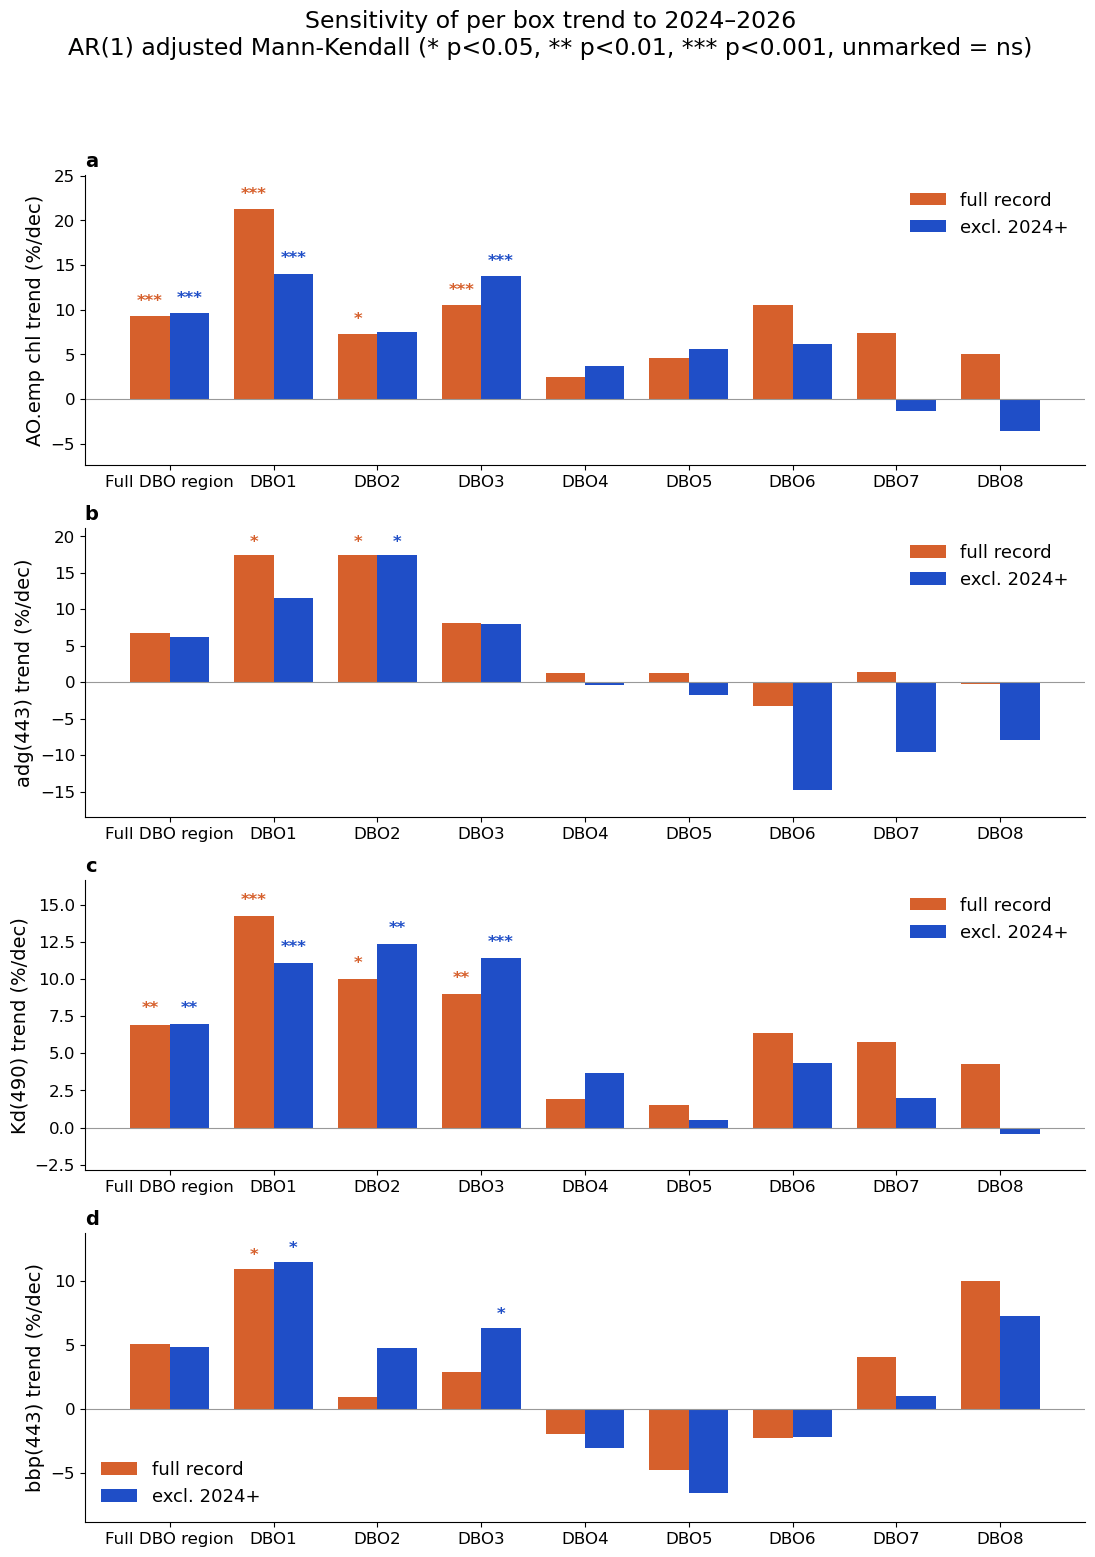

In [9]:
# --- fonts: one place to change them all ---
FS_SUP, FS_LETTER, FS_YLAB, FS_TICK, FS_LEG_B, FS_STAR = 17, 14, 14, 12, 13, 12

fig, axes = plt.subplots(len(series), 1, figsize=(11, 3.9 * len(series)), sharex=False)
axes = np.atleast_1d(axes)

for ax, key in zip(axes, series):
    p = PRODUCTS[key]; tbl = tail_tables[key]
    x = np.arange(len(tbl)); w = 0.38
    span = float(np.nanmax(np.abs(np.concatenate(
        [tbl["%/dec_full"].values, tbl[c_pe].values]))))
    pad = 0.04 * span                                   # gap between a bar tip and its star

    for vcol, pcol, dx, col, lab in (("%/dec_full", "p_full", -w/2, "#d6602c", "full record"),
                                     (c_pe,         c_pp,     +w/2, "#1f4ec7", f"excl. {CUTOFF}+")):
        vals = tbl[vcol].values; ps = tbl[pcol].values
        ax.bar(x + dx, vals, w, label=lab, color=col)
        for xi, v, pv in zip(x + dx, vals, ps):
            st = _stars(pv)
            if st in ("ns", "n/a") or not np.isfinite(v): continue
            up = v >= 0
            ax.text(xi, v + (pad if up else -pad), st, ha="center",
                    va="bottom" if up else "top", fontsize=FS_STAR, color=col,
                    fontweight="bold", clip_on=False)

    ax.axhline(0, color="0.6", lw=0.8)
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo - 0.12 * span, hi + 0.12 * span)     # headroom for the stars
    ax.set_xticks(x); ax.set_xticklabels(tbl.index, fontsize=FS_TICK)
    ax.tick_params(axis="y", labelsize=FS_TICK)
    ax.set_ylabel(f"{p['label']} trend (%/dec)", fontsize=FS_YLAB)
    ax.set_title(p["letter"], loc="left", fontweight="bold", fontsize=FS_LETTER)
    ax.legend(frameon=False, fontsize=FS_LEG_B)
    for spn in ("top", "right"): ax.spines[spn].set_visible(False)

fig.suptitle("Sensitivity of per box trend to 2024–2026\n"
             "AR(1) adjusted Mann-Kendall (* p<0.05, ** p<0.01, *** p<0.001, unmarked = ns)",
             fontsize=FS_SUP, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.955])
fig.savefig(OUTDIR / f"tail_sensitivity_{CUTOFF}_4panel_stars.png", dpi=200, bbox_inches="tight")
print("saved", OUTDIR / f"tail_sensitivity_{CUTOFF}_4panel_stars.png")
plt.show()
